### DDI-Ceiling: Measuring Interaction Signal in FAERS Reports and Auditing a DrugBank DDI Benchmark

This notebook demonstrates how to use **DDI-Ceiling** to measure how much drug-drug interaction (DDI) signal
adverse-event reports contain, and how much of a benchmark score a model earns from the interaction itself.

#### Overview

DDI detectors are scored against curated references, but the reports they read may not contain enough interaction
signal for any detector to do well. DDI-Ceiling models each report count as the count expected from the two drugs
taken separately plus a latent excess. Deconvolution ceiling estimation (DCE) fits the distribution of that excess
for interacting and non-interacting pairs and returns the best AUROC that any statistic of the reports can reach.

Benchmarks raise a related problem: with randomly sampled negatives, a model can score well by learning which drugs
are frequent. The propensity-matched audit (PMA) replaces each negative by a pair of equally frequent drugs, so the
AUROC a model keeps is earned from the pair.

#### Workflow

1. Load the FAERS table for the CRESCENDDI reference set and the DrugBank DDI network
2. Explore the two report channels: co-exposure and reporter attribution
3. Estimate the ceiling of each channel with DCE
4. Forecast the AUROC of a channel at other report volumes
5. Audit the DrugBank DDI benchmark with PMA

## Setup and Imports

In [1]:
import os
import sys
import urllib.request
sys.path.append('../src/')

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sps
import matplotlib
import matplotlib.pyplot as plt

import ddiceil

print(f"numpy: {np.__version__}\n"
      f"scipy: {scipy.__version__}\n"
      f"pandas: {pd.__version__}\n"
      f"matplotlib: {matplotlib.__version__}")

numpy: 1.26.4
scipy: 1.11.0
pandas: 1.5.3
matplotlib: 3.10.9


#### Data available from here:

- `datasets/faers_crescenddi.csv.gz` (included in this repository): one row per CRESCENDDI control (a drug pair and
  an adverse event) with at least one FAERS report naming both drugs. Built from the FAERS quarterly files
  2014Q3 to 2026Q2 (16.2 million deduplicated reports) and the CRESCENDDI reference set (Kontsioti et al., 2022).
- `datasets/ChCh-Miner_durgbank-chem-chem.tsv.gz`: the DrugBank DDI network from Stanford BioSNAP, downloaded
  by the next cell if it is not already there.

In [2]:
os.makedirs('../datasets', exist_ok=True)
ddi_path = '../datasets/ChCh-Miner_durgbank-chem-chem.tsv.gz'
if not os.path.exists(ddi_path):
    urllib.request.urlretrieve('https://snap.stanford.edu/biodata/datasets/10001/files/ChCh-Miner_durgbank-chem-chem.tsv.gz', ddi_path)

#### Load Datasets

Each FAERS row carries two report channels, each as a signal count `F`, the number of reports it is counted in `n`,
and the logit of the rate expected from the two drugs' single-drug data, `logit_r`:

- **co-exposure**: `F` = reports naming both drugs and the event, out of `n` = all reports naming both drugs; this is
  the channel used by disproportionality statistics such as Omega
- **attribution**: `F` = those reports in which the reporter attributed the event to an interaction, out of `n` =
  reports naming both drugs and the event

`label` is 1 for a positive control (a documented interaction) and 0 for a negative control. `stratum` is the
quintile of the stronger single-drug association with the event, used to remove the single-drug shortcut.

In [3]:
faers = pd.read_csv('../datasets/faers_crescenddi.csv.gz')
y = faers['label'].values
print(f"{len(faers):,} controls: {y.sum():,} positive, {(1 - y).sum():,} negative, "
      f"{faers[['drug_a', 'drug_b']].drop_duplicates().shape[0]:,} drug pairs")
faers.head()

13,338 controls: 8,849 positive, 4,489 negative, 8,253 drug pairs


,drug_a,drug_b,event,label,stratum,coexposure_F,coexposure_n,coexposure_logit_r,attribution_F,attribution_n,attribution_logit_r
0,ABCIXIMAB,ALPRAZOLAM,5093,0,0,0,2,-3.717995,0,0,-1.976248
1,ABCIXIMAB,ALTEPLASE,7230,1,4,2,14,-2.125493,0,2,-2.038116
2,ABCIXIMAB,APIXABAN,7230,1,4,0,1,-2.302142,0,0,-2.032248
3,ABCIXIMAB,CELECOXIB,7230,1,4,0,1,-2.487281,0,0,-2.059859
4,ABCIXIMAB,CITALOPRAM,7230,1,4,0,1,-2.507677,0,0,-1.864369


In [4]:
ddi = pd.read_csv(ddi_path, sep='\t', header=None, names=['a', 'b'], comment='#')
drugs = {x: i for i, x in enumerate(sorted(set(ddi.a) | set(ddi.b)))}
u, v = ddi.a.map(drugs).values, ddi.b.map(drugs).values
edges = np.unique(np.stack([np.minimum(u, v), np.maximum(u, v)], 1)[u != v], axis=0)
n_drugs = len(drugs)
print(f"DrugBank DDI network: {n_drugs:,} drugs, {len(edges):,} interactions")

DrugBank DDI network: 1,514 drugs, 48,514 interactions


#### Data Exploration

Most controls have few reports, so any statistic computed from them is noisy. Reporter attribution is sparse: most
co-reports never flag an interaction.

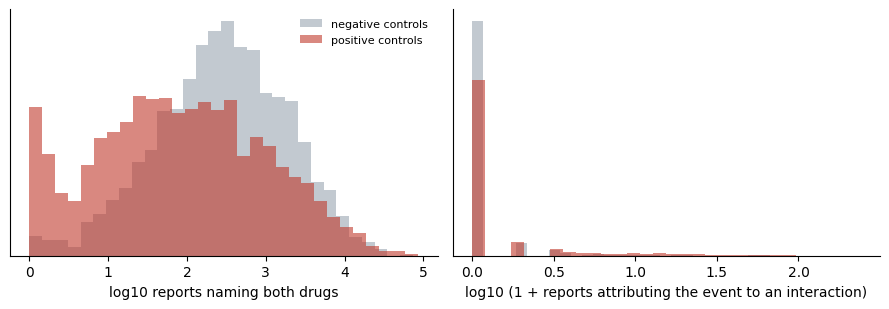

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for k, (lab, col) in enumerate([("negative controls", "#9aa5b1"), ("positive controls", "#c0392b")]):
    m = y == k
    ax[0].hist(np.log10(faers.loc[m, 'coexposure_n']), bins=30, alpha=0.6, color=col, label=lab, density=True)
    ax[1].hist(np.log10(1 + faers.loc[m, 'attribution_F']), bins=30, alpha=0.6, color=col, label=lab, density=True)
ax[0].set_xlabel("log10 reports naming both drugs")
ax[1].set_xlabel("log10 (1 + reports attributing the event to an interaction)")
ax[0].legend(frameon=False, fontsize=8)
for a in ax:
    a.set_yticks([])
    a.spines[['right', 'top']].set_visible(False)
plt.tight_layout()
plt.show()

#### Estimate the Ceiling of Each Report Channel

`ddiceil.dce` fits the latent-excess distributions of the two classes and scores every control by the cross-fitted
likelihood ratio (DCE-LR). Computing its AUROC within the single-drug strata gives the shortcut-free ceiling: the best
AUROC any statistic of the channel can reach once single-drug information is removed. The interval is a two-way
drug-cluster bootstrap.

In [6]:
pair_ids = {p: i for i, p in enumerate(sorted(set(faers.drug_a) | set(faers.drug_b)))}
a_idx, b_idx = faers.drug_a.map(pair_ids).values, faers.drug_b.map(pair_ids).values
strata = faers['stratum'].values

ceilings = {}
for channel in ('coexposure', 'attribution'):
    F, n, logit_r = (faers[f'{channel}_{c}'].values for c in ('F', 'n', 'logit_r'))
    fit = ddiceil.dce(y, F, n, logit_r)
    ceiling = ddiceil.stratified_auroc(y, fit['lr'], strata)
    ci = ddiceil.drug_bootstrap(a_idx, b_idx, len(pair_ids), lambda w: ddiceil.stratified_auroc(y, fit['lr'], strata, w), B=1000)
    ceilings[channel] = (ceiling, ci)
    print(f"{channel:12s} shortcut-free ceiling {ceiling:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]")

coexposure   shortcut-free ceiling 0.521 [0.491, 0.553]


attribution  shortcut-free ceiling 0.661 [0.632, 0.686]


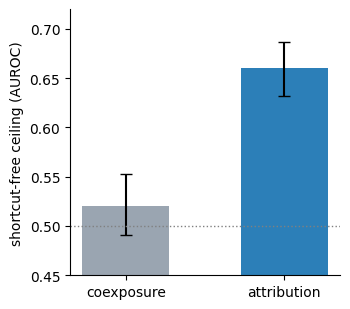

In [7]:
fig, ax = plt.subplots(figsize=(3.6, 3.2))
names = list(ceilings)
vals = [ceilings[k][0] for k in names]
err = np.array([[ceilings[k][0] - ceilings[k][1][0], ceilings[k][1][1] - ceilings[k][0]] for k in names]).T
ax.bar(names, vals, yerr=err, capsize=4, color=["#9aa5b1", "#2c7fb8"], width=0.55)
ax.axhline(0.5, color="grey", ls=":", lw=1)
ax.set_ylim(0.45, 0.72)
ax.set_ylabel("shortcut-free ceiling (AUROC)")
ax.spines[['right', 'top']].set_visible(False)
plt.tight_layout()
plt.show()

Co-reporting counts carry little interaction signal once single-drug information is removed; reports in which the
reporter attributed the harm to an interaction carry clearly more. No detector built on co-exposure counts alone can
do much better than chance on this reference set, whatever its architecture.

#### Forecast the AUROC at Other Report Volumes

How much accuracy would more reports add? We keep each report with probability 1/4, fit DCE on that quarter only,
and forecast the AUROC that raw attribution (observed over expected attribution count) reaches at other report
volumes. Up to 100% the forecast can be checked against the reports themselves; beyond that it shows what two or
four times the reports would add.

In [8]:
F, n, logit_r = (faers[f'attribution_{c}'].values for c in ('F', 'n', 'logit_r'))
rng = np.random.default_rng(0)

def raw_attribution(F, n):
    return np.log((F + 0.5) / (n / (1 + np.exp(-logit_r)) + 0.5))

def keep_reports(frac):
    F_f = rng.binomial(F, frac)
    return F_f, F_f + rng.binomial(n - F, frac)

F25, n25 = keep_reports(0.25)
fit25 = ddiceil.dce(y, F25, n25, logit_r)

fractions = [0.125, 0.25, 0.5, 1.0]
observed, forecast = [], []
for f in fractions:
    F_f, n_f = (F, n) if f == 1.0 else keep_reports(f)
    observed.append(ddiceil.auroc(y, raw_attribution(F_f, n_f)))
    forecast.append(ddiceil.forecast_auroc(y, n_f, logit_r, fit25['law0'], fit25['law1']))
more = [2.0, 4.0]
forecast_more = [ddiceil.forecast_auroc(y, k * n, logit_r, fit25['law0'], fit25['law1']) for k in more]

for f, o, p in zip(fractions, observed, forecast):
    print(f"{f:5.3f} of reports   forecast {p:.3f}   observed {o:.3f}")
for k, p in zip(more, forecast_more):
    print(f"{k:5.1f} x reports    forecast {p:.3f}")

0.125 of reports   forecast 0.585   observed 0.583
0.250 of reports   forecast 0.615   observed 0.613
0.500 of reports   forecast 0.651   observed 0.649
1.000 of reports   forecast 0.683   observed 0.676
  2.0 x reports    forecast 0.692
  4.0 x reports    forecast 0.698


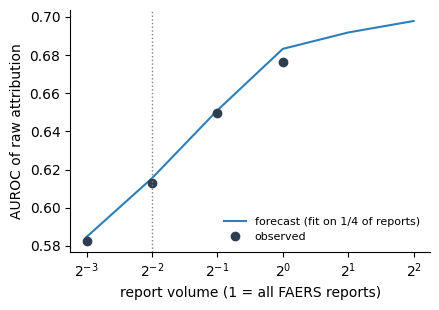

In [9]:
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.plot(fractions + more, forecast + forecast_more, "-", color="#2c7fb8", label="forecast (fit on 1/4 of reports)")
ax.plot(fractions, observed, "o", color="#2c3e50", label="observed")
ax.axvline(0.25, color="grey", ls=":", lw=1)
ax.set_xscale("log", base=2)
ax.set_xlabel("report volume (1 = all FAERS reports)")
ax.set_ylabel("AUROC of raw attribution")
ax.legend(frameon=False, fontsize=8)
ax.spines[['right', 'top']].set_visible(False)
plt.tight_layout()
plt.show()

#### Audit a DDI Benchmark with PMA

We split the DrugBank DDI network as a link-prediction benchmark (85% training, 10% test interactions) and score the
test interactions with three label-free predictors computed on the training graph:

- **node degree**: how many interactions each drug has in training; it knows nothing about the pair
- **common neighbours**: how many interaction partners the two drugs share
- **L3 paths**: degree-normalised paths of length three between the two drugs

Each is scored against the usual random negatives and against PMA negatives, which keep one drug of each test
interaction and replace the other by a drug in the same training-degree decile.

In [10]:
rng = np.random.default_rng(0)
p = rng.permutation(len(edges))
train, test = edges[p[:int(0.85 * len(edges))]], edges[p[int(0.90 * len(edges)):]]
degree = np.bincount(train.ravel(), minlength=n_drugs).astype(float)
edge_set = set(map(tuple, edges))
is_positive = lambda a, b: (min(a, b), max(a, b)) in edge_set

A = sps.coo_matrix((np.ones(2 * len(train)), (np.r_[train[:, 0], train[:, 1]], np.r_[train[:, 1], train[:, 0]])), shape=(n_drugs, n_drugs)).tocsr()
inv_sqrt = sps.diags(1 / np.sqrt(np.maximum(degree, 1)))
P3, Q3 = (A @ inv_sqrt @ A).tocsr(), (A @ inv_sqrt).T.tocsr()
scorers = {
    'node degree': lambda X: np.log1p(degree[X[:, 0]]) + np.log1p(degree[X[:, 1]]),
    'common neighbours': lambda X: np.asarray(A[X[:, 0]].multiply(A[X[:, 1]]).sum(1)).ravel(),
    'L3 paths': lambda X: np.asarray(P3[X[:, 0]].multiply(Q3[X[:, 1]]).sum(1)).ravel(),
}

random_neg = []
while len(random_neg) < len(test):
    a, b = rng.integers(0, n_drugs, 2)
    if a != b and not is_positive(a, b):
        random_neg.append((min(a, b), max(a, b)))
random_neg = np.array(random_neg)
pma_neg, kept = ddiceil.pma_negatives(test, ddiceil.propensity_bins(degree), is_positive, rng)
print(f"{len(kept):,} of {len(test):,} test interactions matched")

audit = {}
for name, score in scorers.items():
    a_rand = ddiceil.auroc(np.r_[np.ones(len(test)), np.zeros(len(random_neg))], np.r_[score(test), score(random_neg)])
    a_pma = ddiceil.auroc(np.r_[np.ones(len(kept)), np.zeros(len(pma_neg))], np.r_[score(test[kept]), score(pma_neg)])
    audit[name] = (a_rand, a_pma)
    print(f"{name:18s} random {a_rand:.3f}   PMA {a_pma:.3f}   shortcut share {ddiceil.shortcut_share(a_rand, a_pma):.2f}")

4,852 of 4,852 test interactions matched
node degree        random 0.884   PMA 0.509   shortcut share 0.98
common neighbours  random 0.908   PMA 0.680   shortcut share 0.56


L3 paths           random 0.952   PMA 0.795   shortcut share 0.35


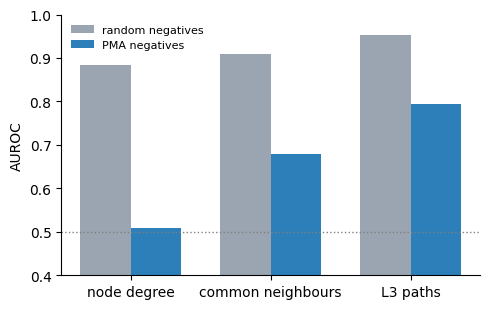

In [11]:
fig, ax = plt.subplots(figsize=(5, 3.2))
x = np.arange(len(audit))
ax.bar(x - 0.18, [v[0] for v in audit.values()], 0.36, color="#9aa5b1", label="random negatives")
ax.bar(x + 0.18, [v[1] for v in audit.values()], 0.36, color="#2c7fb8", label="PMA negatives")
ax.axhline(0.5, color="grey", ls=":", lw=1)
ax.set_xticks(x)
ax.set_xticklabels(list(audit))
ax.set_ylim(0.4, 1.0)
ax.set_ylabel("AUROC")
ax.legend(frameon=False, fontsize=8)
ax.spines[['right', 'top']].set_visible(False)
plt.tight_layout()
plt.show()

Against random negatives, node degree alone looks like a strong DDI predictor. Against PMA negatives it falls to
chance, and the share of each predictor's AUROC that survives is what it learned about the pair.